# 05 After the sale: does a building's record change when it is sold?

A staggered event study around whole-building arms-length sales, split by whether the building was silent before the sale. Honest framing up front: this is observational, the estimand is the change in *recorded* activity, and the interesting subgroup (silent buildings) is small.
Source tables: `reports/phase5/*.csv`. Full write-up and limits: [`docs/sales_phase5.md`](../docs/sales_phase5.md).

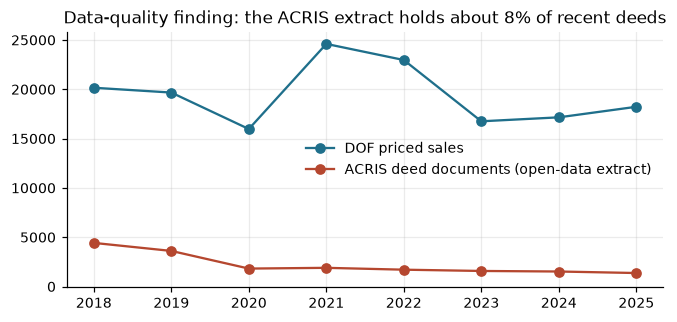

In [1]:
from nbutil import *
R5 = REPORTS / "phase5"
cov = pd.read_csv(R5 / "acris_vs_dof_coverage.csv")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(cov.year, cov.dof_priced_sales, "-o", color=BLUE, label="DOF priced sales")
ax.plot(cov.year, cov.acris_deed_documents, "-o", color=RED, label="ACRIS deed documents (open-data extract)")
ax.set_ylim(0); ax.legend(frameon=False); ax.set_title("Data-quality finding: the ACRIS extract holds about 8% of recent deeds")
plt.show()

The plan was to use ACRIS deeds. A pre-declared coverage rule (usable only if the source's recent volume is at least 60% of an independent count) failed at 8%, so the study uses the Department of Finance sales files instead, which have no party names. **No owner or buyer names are used anywhere.**

## Who is treated, who is a control

In [2]:
att = pd.read_csv(R5 / "study_attrition.csv"); att["n"] = att.n.map("{:,}".format); att

,step,n
0,DOF sale rows in the data,"301,701"
1,whole-building rows on analysis buildings (any...,"42,416"
2,arms-length proxy sales 2018 onward,"17,553"
3,distinct buildings with such a sale,"15,766"
4,"first sale with a full window (8 before, 8 aft...","8,500"
5,analysis buildings with no whole-building DOF ...,"70,157"
6,in the marts (analysis universe) - treated,"8,500"
7,in the marts (analysis universe) - never-treat...,"70,157"


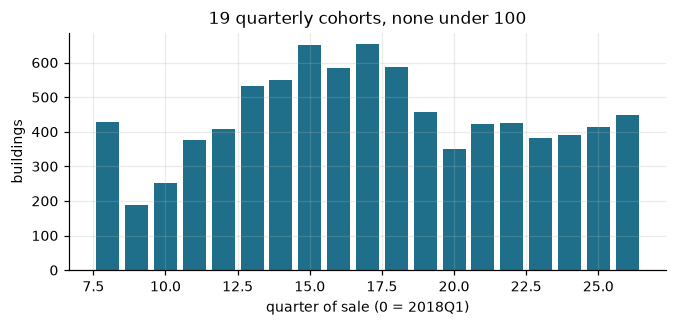

,,never sold,sold
0,units,15.63,8.00
1,brooklyn,0.78,0.74
2,built_pre1930,0.49,0.54
3,viol_per_unit_2018_19,0.64,0.94
4,any_complaint_2018_19,0.28,0.27


In [3]:
co = pd.read_csv(R5 / "study_cohorts.csv")
fig, ax = plt.subplots(figsize=(7, 2.8)); ax.bar(co.cohort_quarter_index, co.n_buildings, color=BLUE)
ax.set_xlabel("quarter of sale (0 = 2018Q1)"); ax.set_ylabel("buildings"); ax.set_title("19 quarterly cohorts, none under 100"); plt.show()
pd.read_csv(R5 / "study_balance.csv").rename(columns={"Unnamed: 0": "", "False": "never sold", "True": "sold"}).round(2)

Sold buildings are smaller (8 vs 16 units) and had more violations per unit in 2018-19, which is why controls are reweighted to the treated mix.

## Event study (primary specification)

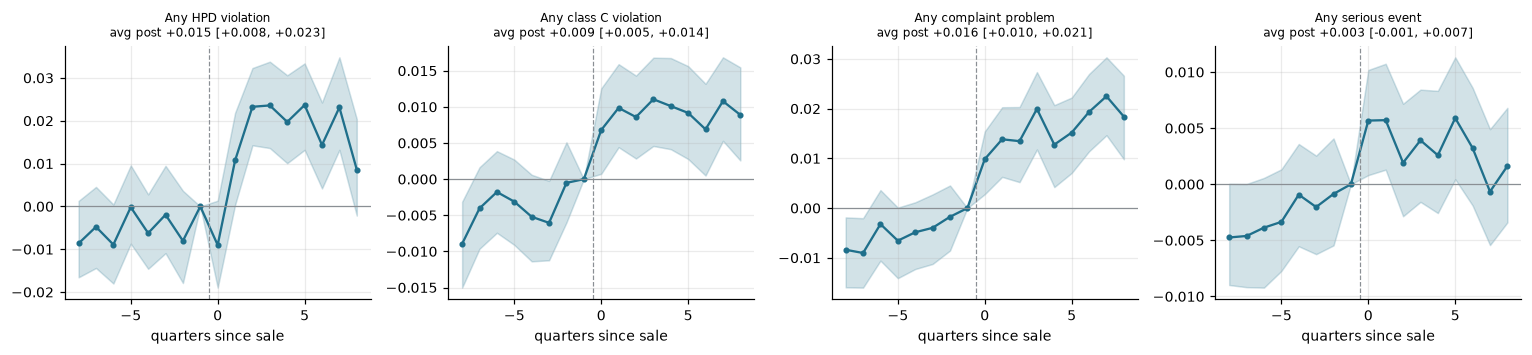

In [4]:
ev = pd.read_csv(R5 / "study_event_time.csv")
res = pd.read_csv(R5 / "study_results.csv")
titles = {"any_violation": "Any HPD violation", "any_class_c": "Any class C violation", "any_complaint": "Any complaint problem", "any_serious": "Any serious event"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3), sharex=True)
for ax, o in zip(axes, titles):
    d = ev[(ev.group == "all") & (ev.spec == "primary") & (ev.outcome == o)]
    d = pd.concat([d, pd.DataFrame([dict(event=-1, theta=0, lo=0, hi=0)])]).sort_values("event")
    ax.fill_between(d.event, d.lo, d.hi, color=BLUE, alpha=0.2); ax.plot(d.event, d.theta, "-o", color=BLUE, ms=3); ax.axhline(0, color=GREY, lw=.8); ax.axvline(-.5, color=GREY, ls="--", lw=.8)
    r = res[(res.group == "all") & (res.spec == "primary") & (res.outcome == o)].iloc[0]
    ax.set_title(f"{titles[o]}\navg post {r.avg_post:+.3f} [{r.avg_post_lo:+.3f}, {r.avg_post_hi:+.3f}]", fontsize=8); ax.set_xlabel("quarters since sale")
plt.tight_layout(); plt.show()

In [5]:
t = res[(res.spec == "primary") & (res.group == "all")][["outcome", "pre_mean_treated", "avg_post", "avg_post_lo", "avg_post_hi", "relative_pct", "adj_post", "adj_post_lo", "adj_post_hi", "pre_trend_p"]]
t.round(4)

,outcome,pre_mean_treated,avg_post,avg_post_lo,avg_post_hi,relative_pct,adj_post,adj_post_lo,adj_post_hi,pre_trend_p
0,any_violation,0.2144,0.0153,0.0082,0.0231,7.1555,0.0142,0.0057,0.0228,0.1110
1,any_class_c,0.0591,0.0091,0.0049,0.0141,15.4469,0.0062,-0.0003,0.0133,0.0187
2,any_complaint,0.1015,0.0161,0.0102,0.0212,15.9156,0.0113,0.0032,0.0182,0.1430
3,any_serious,0.0325,0.0033,-0.0008,0.0071,10.2243,-0.0002,-0.0049,0.0049,0.4142
4,violations_n,1.1220,0.1144,0.0143,0.2095,10.2003,0.0682,-0.0941,0.2085,0.1696
5,complaints_n,0.8075,0.2434,0.1463,0.3287,30.1390,0.2071,0.0671,0.3247,0.1343


Reading the table: violations and complaints rise modestly after a sale (about +7% and +16% relative to the pre-sale rate), serious events do not move detectably. Complaints and class C violations were **already drifting upward before the sale**, so the "after removing the pre-trend" columns are the conservative reading; class C attenuates to roughly zero there.

## Silent vs not silent (sales from 2022Q2, flag at the 2022-01-01 snapshot)

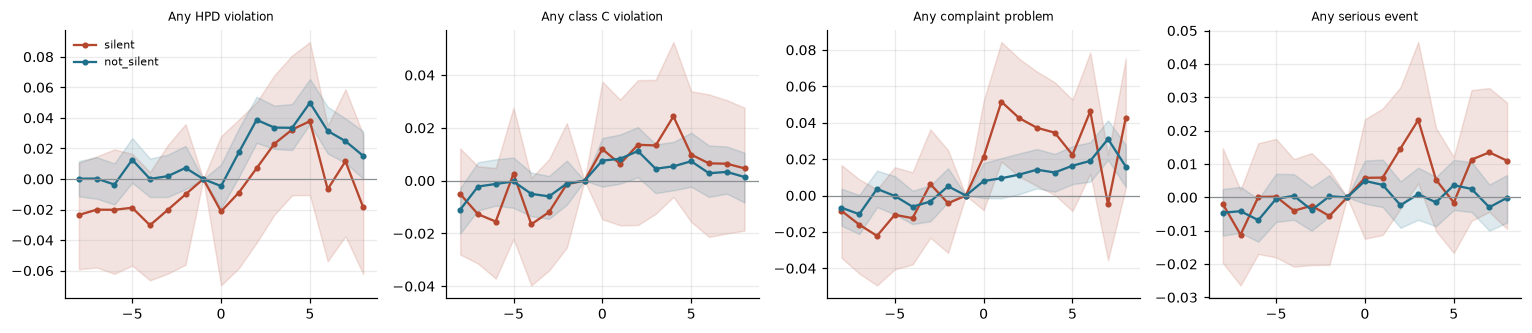

      outcome  diff_silent_minus_not      lo     hi
any_violation                -0.0204 -0.0567 0.0160
  any_serious                 0.0089 -0.0053 0.0218


,group,outcome,n_treated,avg_post,avg_post_lo,avg_post_hi
23,silent,any_violation,453,0.0063,-0.0279,0.0408
24,silent,any_class_c,453,0.0108,-0.0105,0.0290
25,silent,any_complaint,453,0.0326,0.0097,0.0530
26,silent,any_serious,453,0.0099,-0.0030,0.0221
27,silent,violations_n,453,0.1089,-0.1999,0.3901
28,not_silent,any_violation,4027,0.0267,0.0164,0.0377
29,not_silent,any_class_c,4027,0.0058,-0.0010,0.0126
30,not_silent,any_complaint,4027,0.0154,0.0069,0.0237
31,not_silent,any_serious,4027,0.0010,-0.0042,0.0066
32,not_silent,violations_n,4027,0.0980,-0.0735,0.2485


In [6]:
s = res[(res.spec == "primary") & res.group.isin(["silent", "not_silent"])]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.1), sharex=True)
for ax, o in zip(axes, titles):
    for grp, col in [("silent", RED), ("not_silent", BLUE)]:
        d = ev[(ev.group == grp) & (ev.spec == "primary") & (ev.outcome == o)]
        d = pd.concat([d, pd.DataFrame([dict(event=-1, theta=0, lo=0, hi=0)])]).sort_values("event")
        ax.fill_between(d.event, d.lo, d.hi, color=col, alpha=0.15); ax.plot(d.event, d.theta, "-o", color=col, ms=3, label=grp)
    ax.axhline(0, color=GREY, lw=.8); ax.set_title(titles[o], fontsize=8)
axes[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()
print(pd.read_csv(R5 / "study_silent_difference.csv").round(4).to_string(index=False))
s[["group", "outcome", "n_treated", "avg_post", "avg_post_lo", "avg_post_hi"]].round(4)

Only 453 sold buildings were silent at baseline, so intervals are wide and **no difference between silent and not-silent buildings is detectable**.

## Robustness: different control groups

In [7]:
res[(res.group == "all") & (res.outcome.isin(["any_violation", "any_complaint", "any_serious"]))][["spec", "outcome", "avg_post", "avg_post_lo", "avg_post_hi", "pre_trend_p"]].round(4)

,spec,outcome,avg_post,avg_post_lo,avg_post_hi,pre_trend_p
0,primary,any_violation,0.0153,0.0082,0.0231,0.1110
2,primary,any_complaint,0.0161,0.0102,0.0212,0.1430
3,primary,any_serious,0.0033,-0.0008,0.0071,0.4142
6,uncond,any_violation,0.0149,0.0078,0.0221,0.0051
8,uncond,any_complaint,0.0138,0.0084,0.0193,0.6284
9,uncond,any_serious,0.0025,-0.0014,0.0062,0.6834
12,notyet,any_violation,0.0147,0.0068,0.0214,0.0091
14,notyet,any_complaint,0.0137,0.0080,0.0195,0.6610
15,notyet,any_serious,0.0024,-0.0018,0.0063,0.6747


## What this does and does not show
- **Does:** a small, robust-to-control-choice rise in recorded violations and complaints after whole-building sales; no detectable change in serious events; no detectable difference for silent buildings.
- **Does not:** show that sales harm tenants (more records can mean active new management, turnover or more inspection attention); sale timing is not random; LLC-interest transfers are invisible; there is no buyer information by design.
